# Small grid DPsim comparison after powerflow initialization

Fresh, closed-loop 10 s EMT simulations compare the native averaged inverter, DPsim FMI Model Exchange (ME), and DPsim FMI Co-Simulation (CS). Every method uses the same small grid, powerflow operating point, 5 s load step, and fixed timestep for each matched comparison. The native inverter filter is initialized at the same 60 Hz periodic steady state as the FMU’s 5 ms current-response filter.

The native DPsim case at the **same timestep** is the reference for ME and CS. Errors are calculated from the complete, full-resolution traces before they are reduced for plotting. The trace plots show trailing 100 ms RMS error percentages, sampled for display. Native is the zero-error reference.

The cases use 10, 25, 50, 100, 500, and 1000 µs. Results are generated by `run_dpsim_10s_sweep.py` and stored below `build-fmi/small-inverter-grid/results/dpsim_10s_1to1000us_native_pf_init/`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Work both when launched from the repository root and from this notebook folder.
HERE = Path.cwd()
ROOT = HERE if (HERE / "build-fmi").exists() else HERE.parents[2]
OUT = (
    ROOT
    / "build-fmi"
    / "small-inverter-grid"
    / "results"
    / "dpsim_10s_1to1000us_native_pf_init"
)
metrics = json.loads((OUT / "metrics.json").read_text())
steps_us = metrics["configuration"]["steps_us"]
print(
    f"Results: {OUT}\nTimesteps: {steps_us} µs\nDuration: {metrics['configuration']['duration_s']} s; load step: {metrics['configuration']['load_step_s']} s"
)

Results: /home/matthiasmees/dpsim/build-fmi/small-inverter-grid/results/dpsim_10s_1to1000us_native_pf_init
Timesteps: [10, 25, 50, 100, 500, 1000] µs
Duration: 10.0 s; load step: 5.0 s


## Full-run RMS error summary

In [2]:
rows = []
for step in steps_us:
    case = metrics["cases"][str(step)]
    for method in ("me", "cs"):
        result = case["comparisons"][method]
        rows.append(
            {
                "Timestep [µs]": step,
                "Method": method.upper(),
                "Voltage RMS error [%]": result["full_run"]["voltage"][
                    "rms_error_percent"
                ],
                "Current RMS error [%]": result["full_run"]["current"][
                    "rms_error_percent"
                ],
                "Pre-step V error [%]": result["before_load_step"]["voltage"][
                    "rms_error_percent"
                ],
                "Pre-step I error [%]": result["before_load_step"]["current"][
                    "rms_error_percent"
                ],
                "Post-step V error [%]": result["after_load_step"]["voltage"][
                    "rms_error_percent"
                ],
                "Post-step I error [%]": result["after_load_step"]["current"][
                    "rms_error_percent"
                ],
            }
        )
summary = pd.DataFrame(rows)
display(
    summary.style.format(
        {c: "{:.5g}" for c in summary.columns if c not in ("Timestep [µs]", "Method")}
    )
)

,Timestep [µs],Method,Voltage RMS error [%],Current RMS error [%],Pre-step V error [%],Pre-step I error [%],Post-step V error [%],Post-step I error [%]
0,10,ME,1.9952e-10,1.5657e-09,2.6885e-11,1.0438e-09,2.809e-10,1.9526e-09
1,10,CS,0.00075924,0.18926,0.00075534,0.18926,0.00076312,0.18926
2,25,ME,2.6371e-10,2.1832e-09,2.3486e-11,1.167e-09,3.7222e-10,2.8583e-09
3,25,CS,0.0018983,0.4732,0.0018887,0.47321,0.0019078,0.47319
4,50,ME,3.4932e-10,1.6504e-09,1.8886e-11,0,4.9368e-10,2.3338e-09
5,50,CS,0.0037967,0.94659,0.0037789,0.94661,0.0038144,0.94658
6,100,ME,4.4241e-10,8.4159e-09,1.7149e-11,7.0029e-09,6.2546e-10,9.6233e-09
7,100,CS,0.0075918,1.894,0.007567,1.894,0.0076165,1.894
8,500,ME,5.4078e-10,0,1.3169e-11,0,7.6469e-10,0
9,500,CS,0.038412,9.5193,0.038924,9.5193,0.037894,9.5192


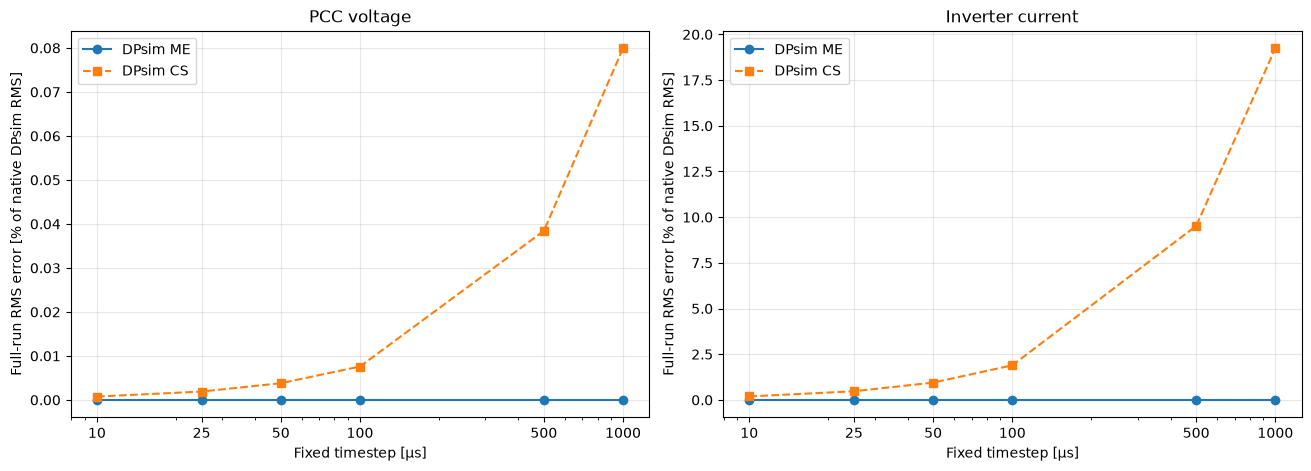

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
for method, style in (("ME", "o-"), ("CS", "s--")):
    frame = summary[summary["Method"] == method]
    axes[0].plot(
        frame["Timestep [µs]"],
        frame["Voltage RMS error [%]"],
        style,
        label=f"DPsim {method}",
    )
    axes[1].plot(
        frame["Timestep [µs]"],
        frame["Current RMS error [%]"],
        style,
        label=f"DPsim {method}",
    )
for ax, title, ylabel in zip(
    axes,
    ("PCC voltage", "Inverter current"),
    (
        "Full-run RMS error [% of native DPsim RMS]",
        "Full-run RMS error [% of native DPsim RMS]",
    ),
):
    ax.set_xscale("log")
    ax.set_xticks(steps_us, labels=[str(x) for x in steps_us])
    ax.set_xlabel("Fixed timestep [µs]")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()

## Full-run RMS error by timestep

Each figure shows the full-run RMS error for ME and CS against native DPsim at the same timestep. Voltage and current use separate axes so each quantity remains readable. The values use every original sample and all three phases; the bars are reported as percentages of the native baseline RMS.

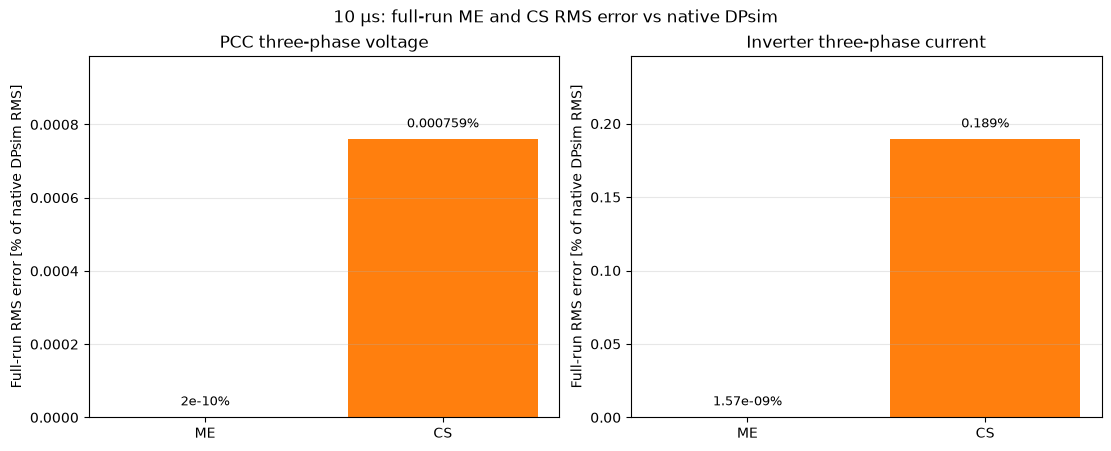

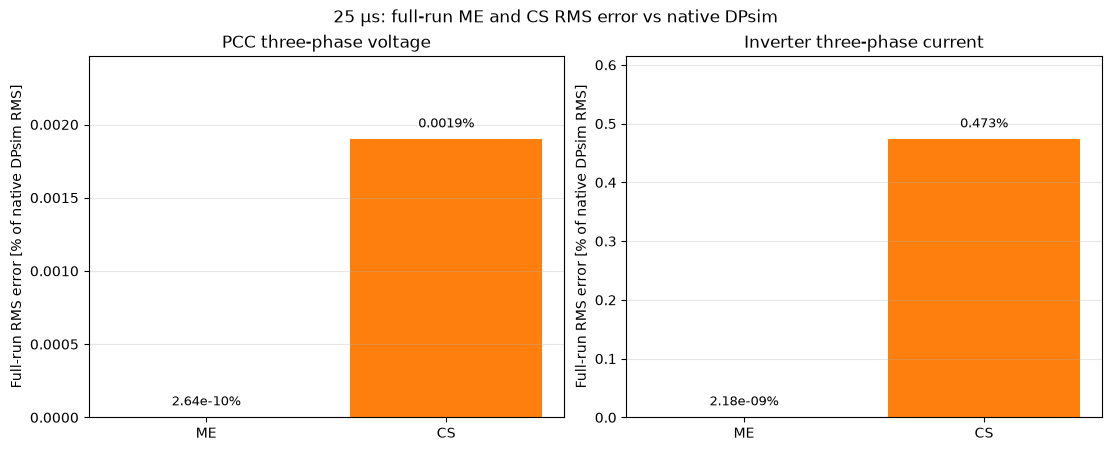

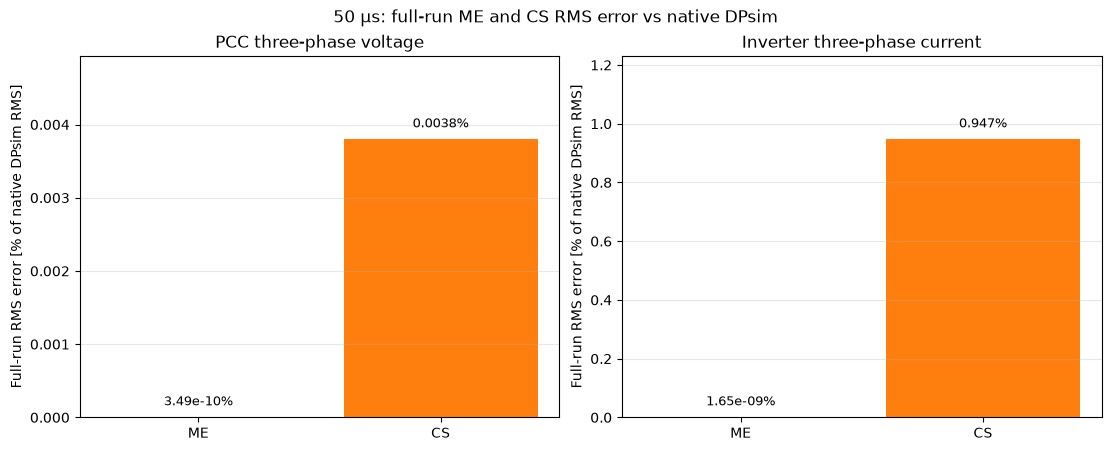

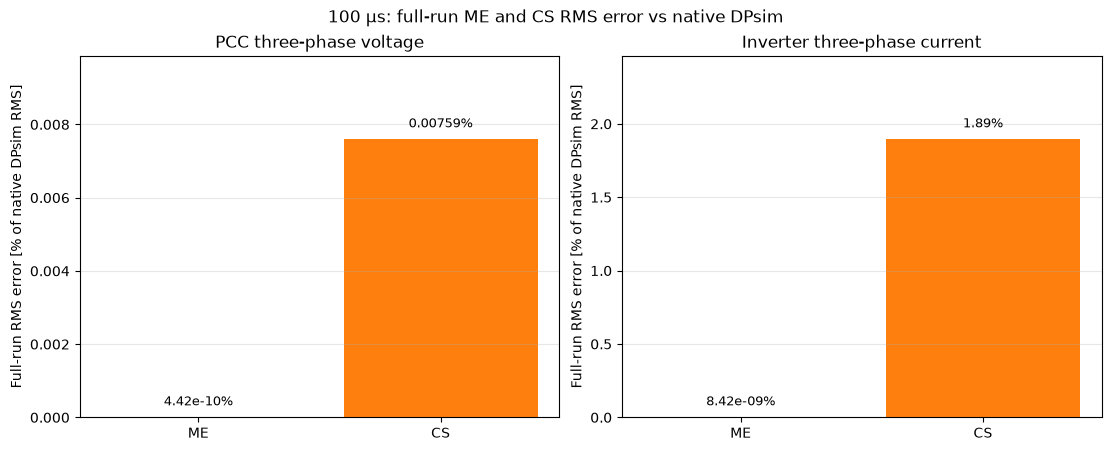

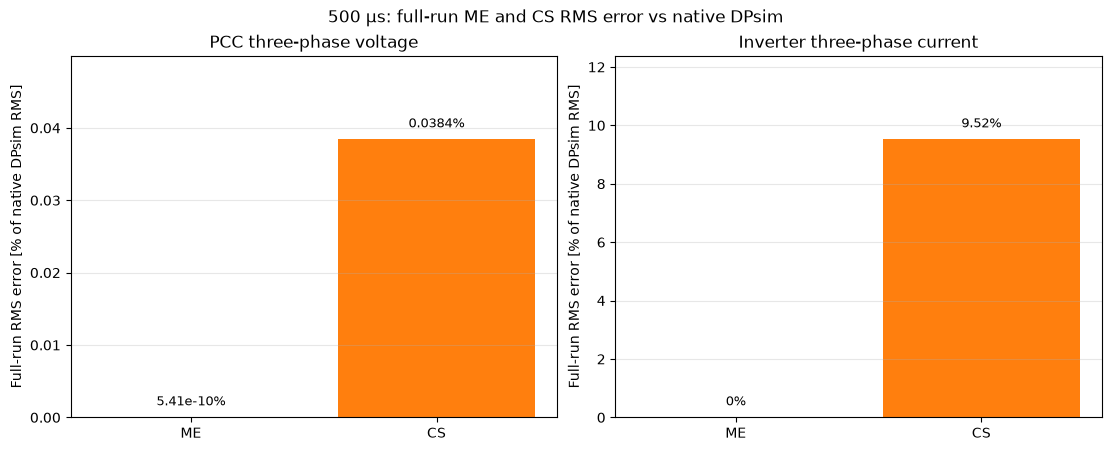

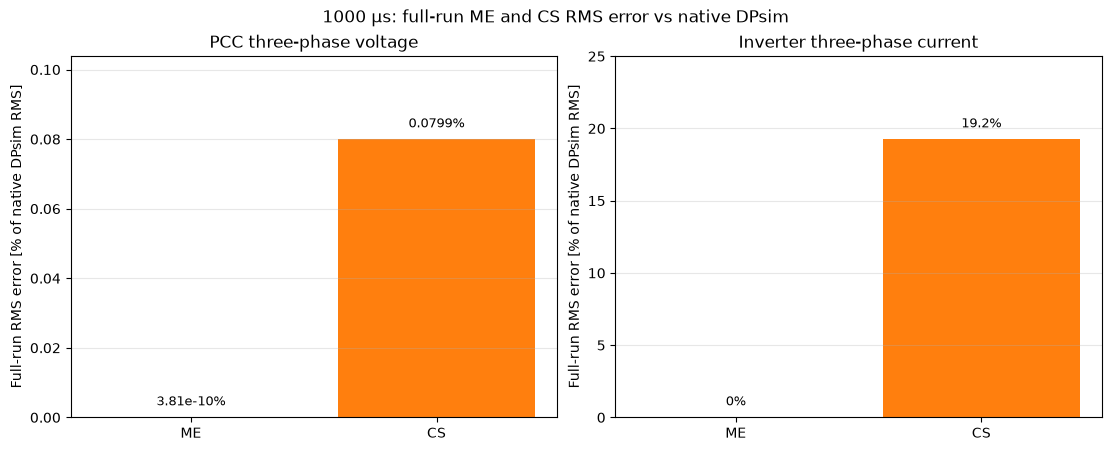

In [4]:
for step in steps_us:
    case = metrics["cases"][str(step)]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
    for ax, quantity, title in zip(
        axes,
        ("voltage", "current"),
        ("PCC three-phase voltage", "Inverter three-phase current"),
    ):
        values = [
            case["comparisons"][method]["full_run"][quantity]["rms_error_percent"]
            for method in ("me", "cs")
        ]
        bars = ax.bar(("ME", "CS"), values, color=("tab:blue", "tab:orange"))
        ymax = max(values) * 1.30 if max(values) > 0 else 1e-12
        ax.set_ylim(0, ymax)
        ax.set_ylabel("Full-run RMS error [% of native DPsim RMS]")
        ax.set_title(title)
        ax.grid(True, axis="y", alpha=0.3)
        for bar, value in zip(bars, values):
            label_y = value + ymax * 0.025 if value > 0 else ymax * 0.025
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                label_y,
                f"{value:.3g}%",
                ha="center",
                va="bottom",
                fontsize=9,
            )
    fig.suptitle(f"{step} µs: full-run ME and CS RMS error vs native DPsim")
    plt.show()

## Error trajectories for every timestep

Each panel compares ME and CS with native DPsim at the same timestep. Curves are trailing 100 ms RMS errors, expressed relative to the native DPsim signal RMS in that same window. The load step is marked at 5 s.

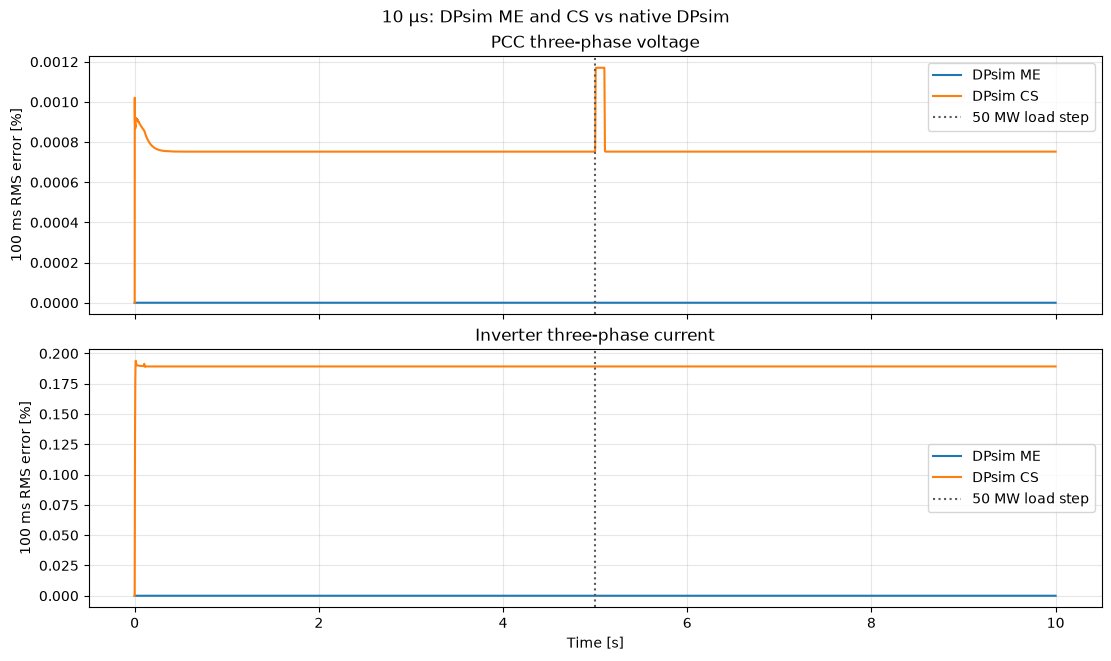

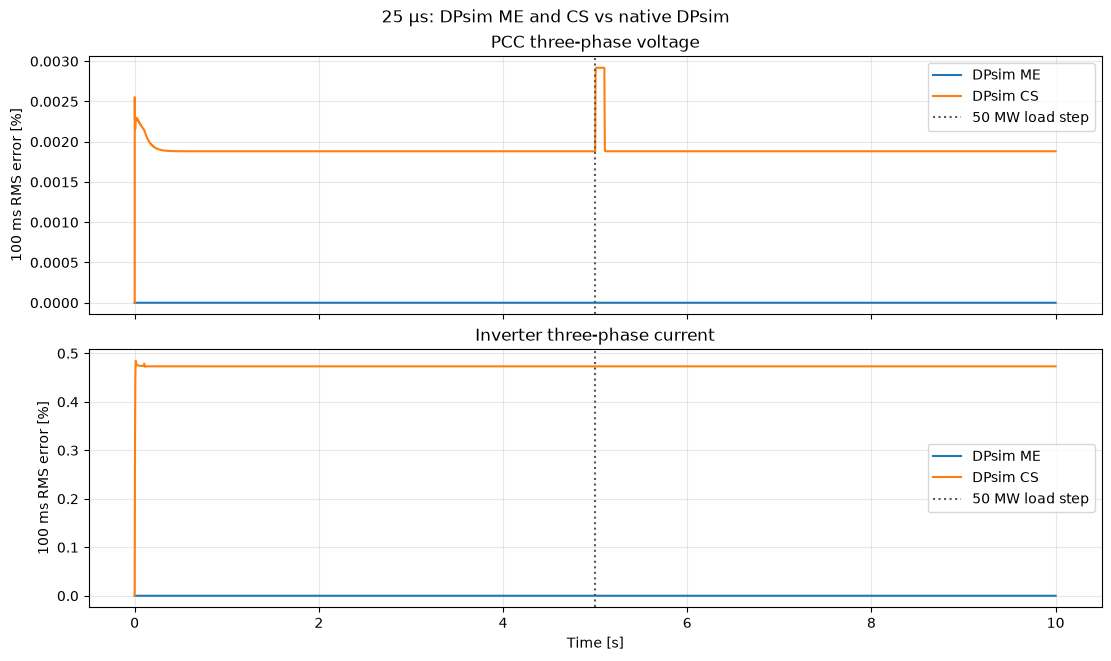

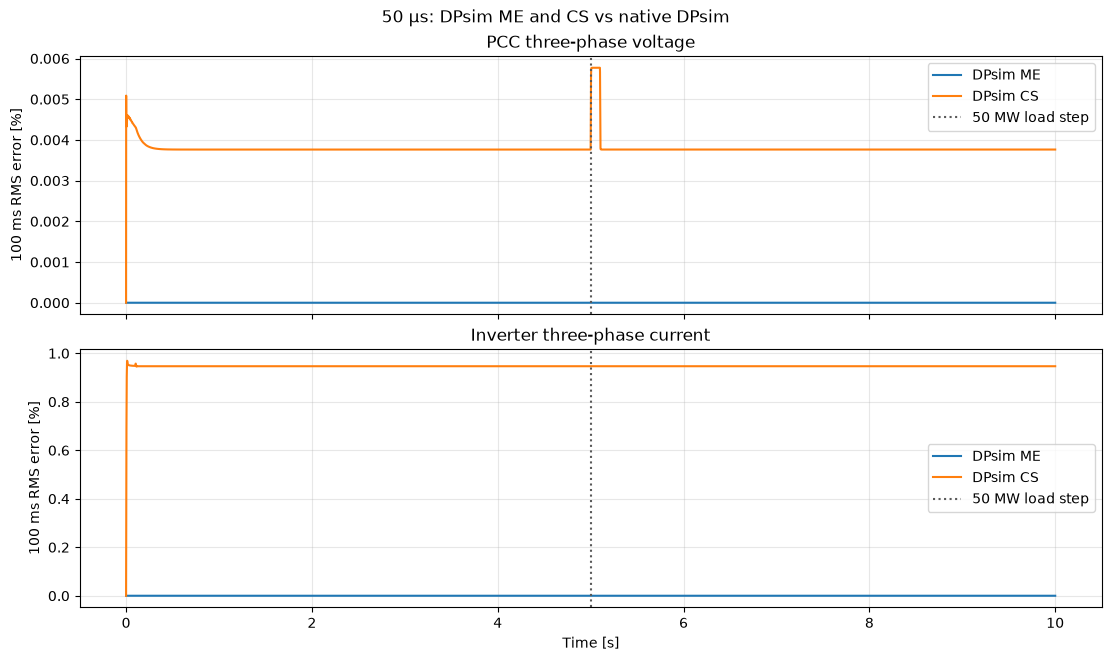

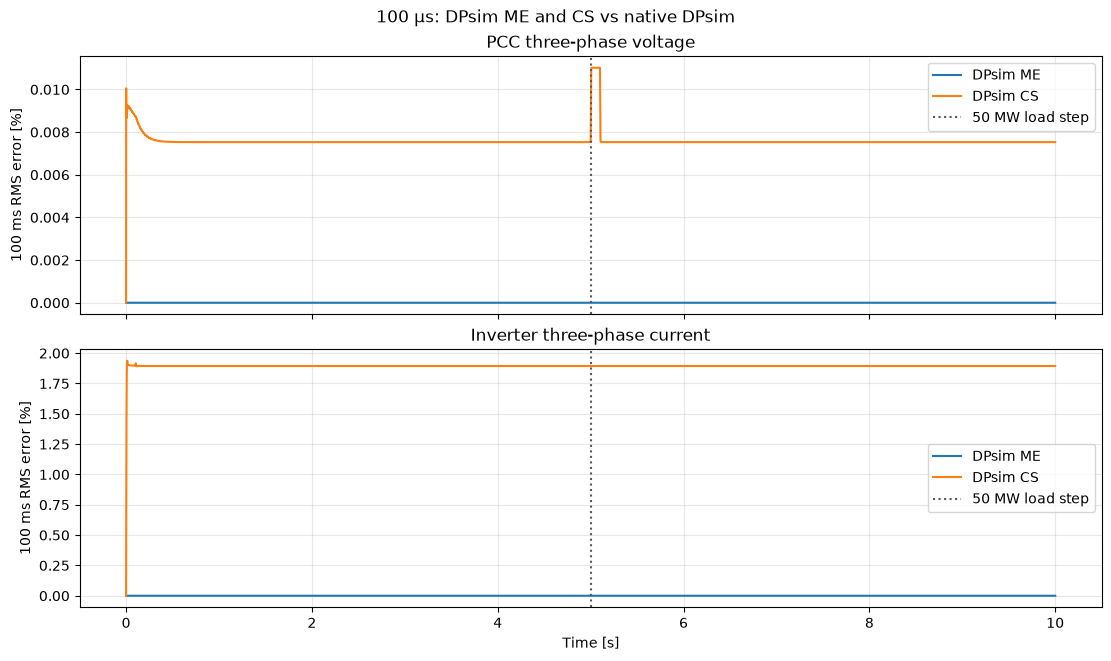

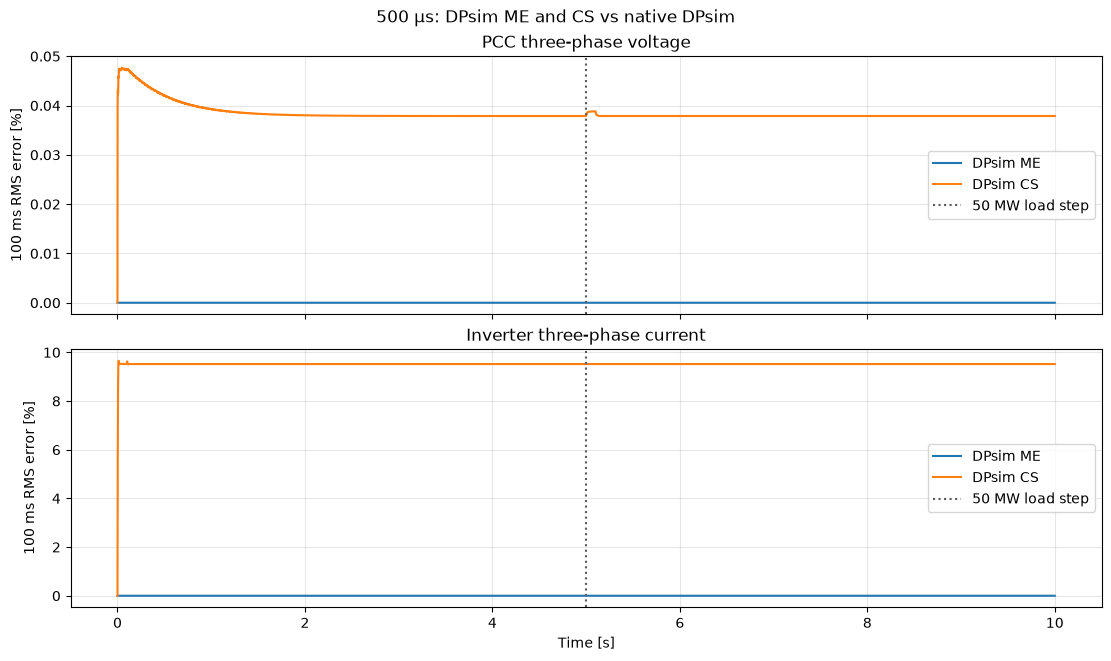

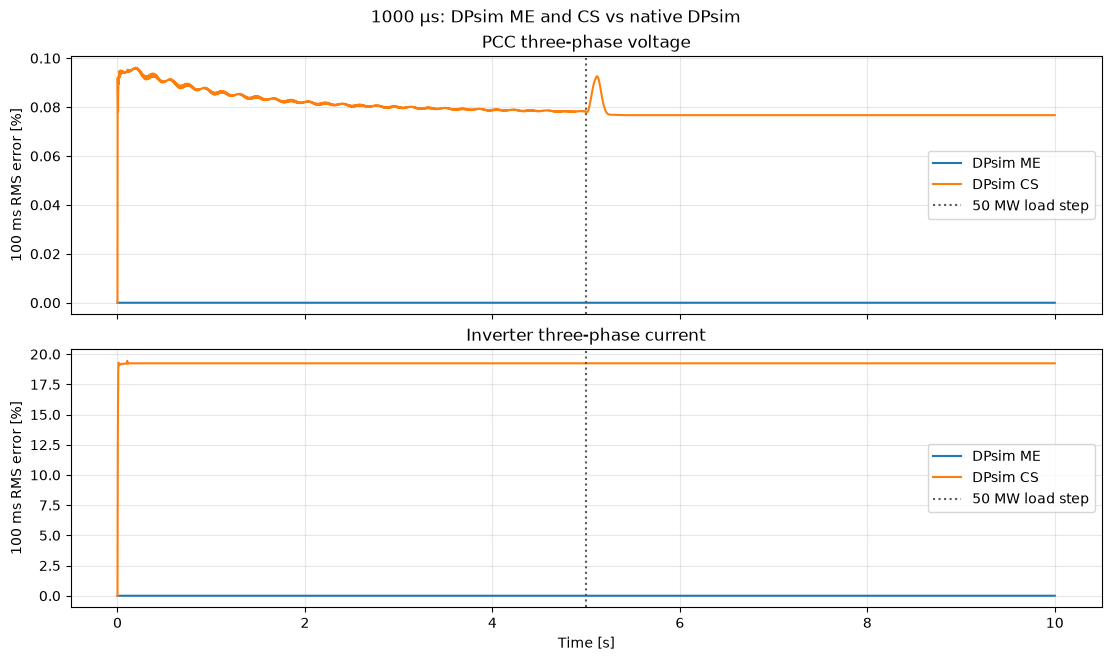

In [5]:
for step in steps_us:
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.5), sharex=True, constrained_layout=True
    )
    for method, color in (("me", "tab:blue"), ("cs", "tab:orange")):
        result = metrics["cases"][str(step)]["comparisons"][method]
        trace = pd.read_csv(result["rolling_error_trace"])
        axes[0].plot(
            trace["time_s"],
            trace["voltage_error_percent_100ms"],
            color=color,
            label=f"DPsim {method.upper()}",
        )
        axes[1].plot(
            trace["time_s"],
            trace["current_error_percent_100ms"],
            color=color,
            label=f"DPsim {method.upper()}",
        )
    for ax, title in zip(
        axes, ("PCC three-phase voltage", "Inverter three-phase current")
    ):
        ax.axvline(
            metrics["configuration"]["load_step_s"],
            color="0.35",
            linestyle=":",
            label="50 MW load step",
        )
        ax.set_ylabel("100 ms RMS error [%]")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        ax.legend()
    axes[1].set_xlabel("Time [s]")
    fig.suptitle(f"{step} µs: DPsim ME and CS vs native DPsim")
    plt.show()

## Phase-a waveforms around the load step

Each timestep has a close-up from 5 ms before to 5 ms after the 50 MW load step. The plots overlay native DPsim, ME, and CS phase-a PCC voltage and inverter current. They use the compact traces retained from each run.

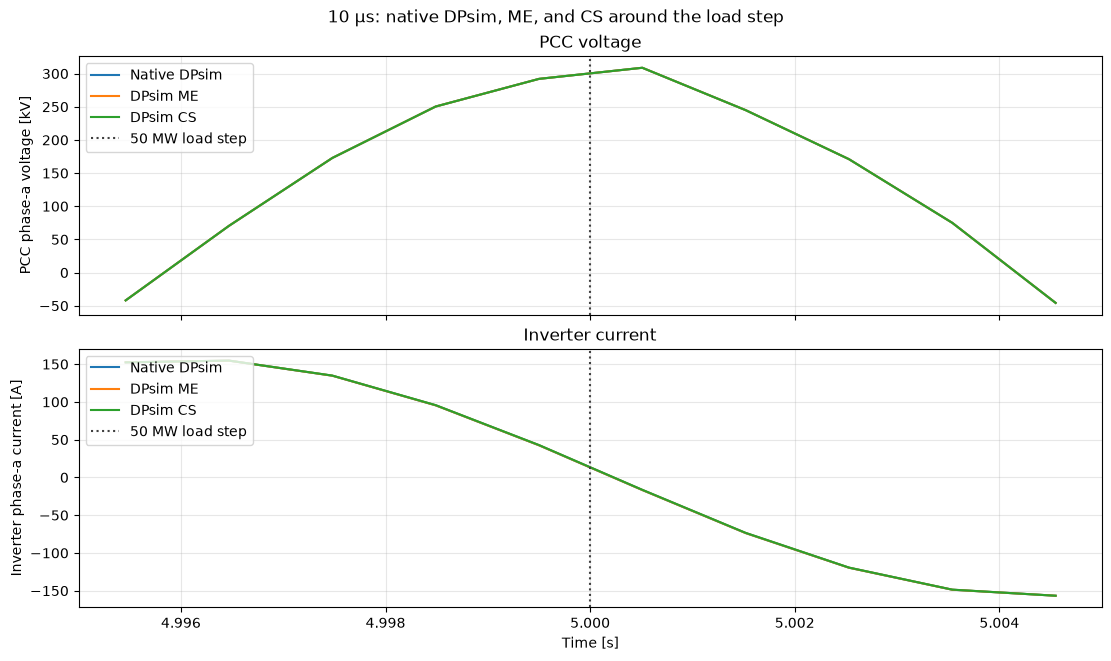

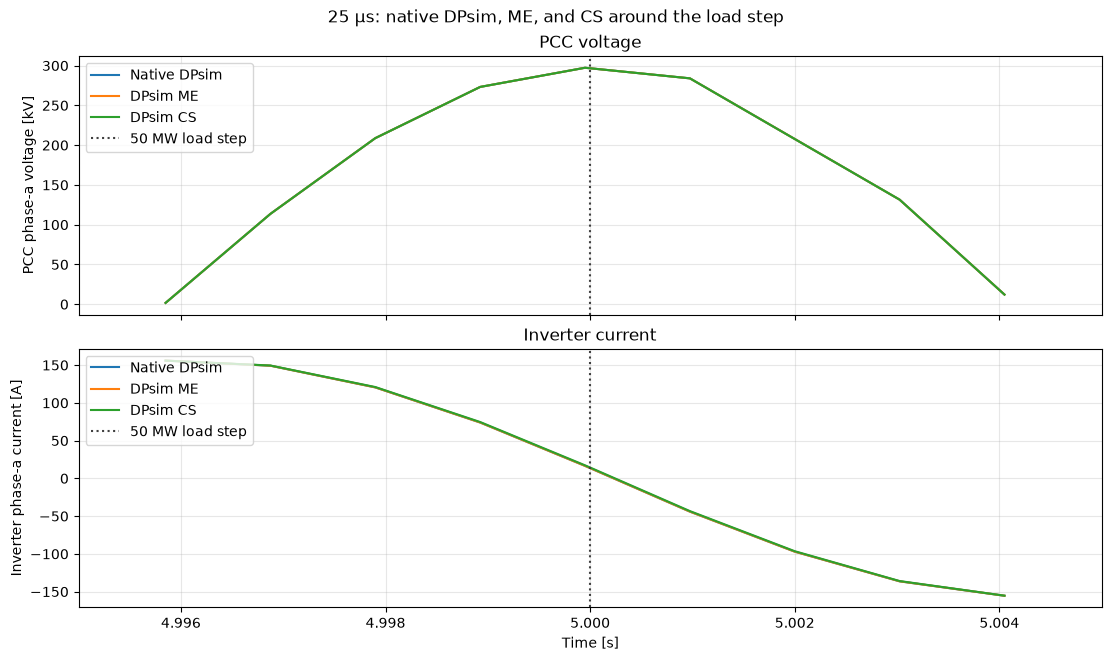

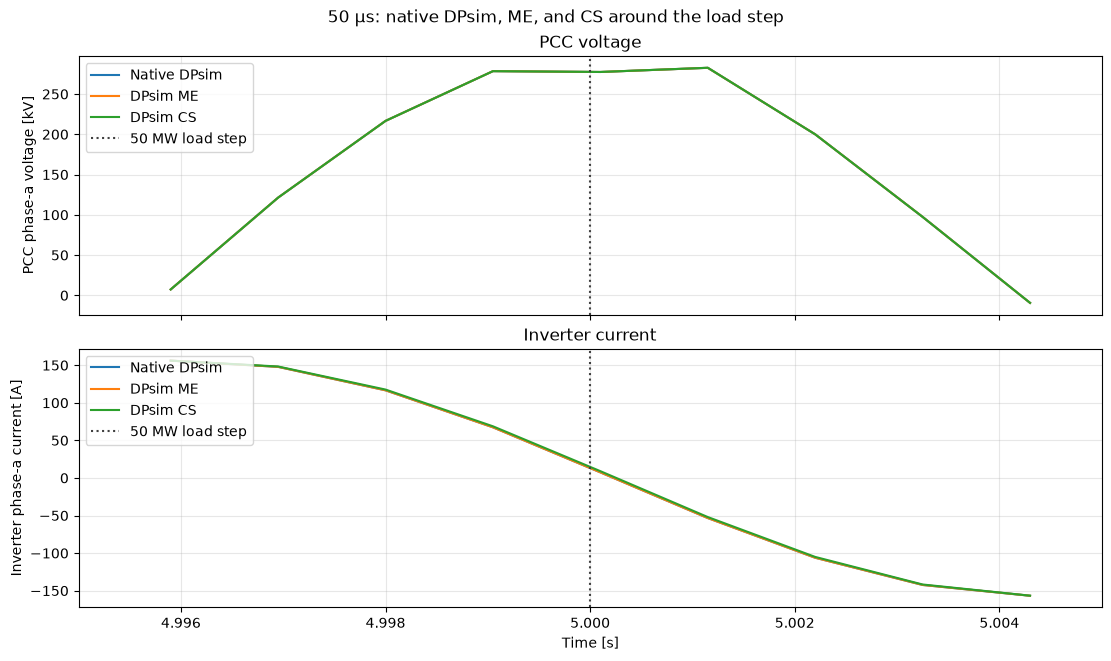

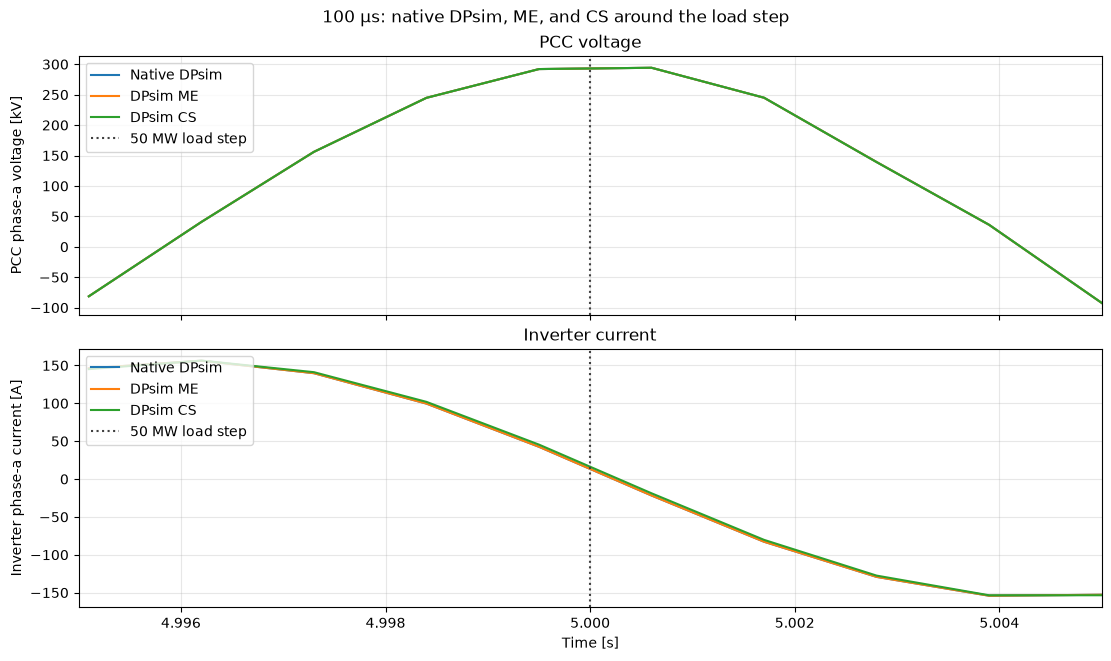

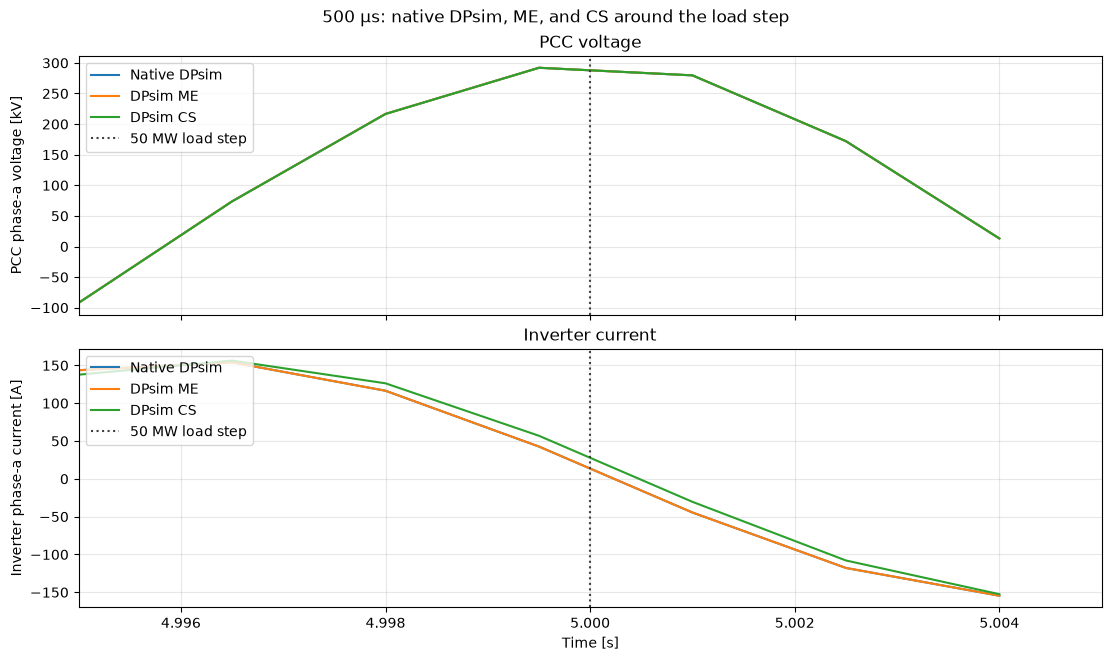

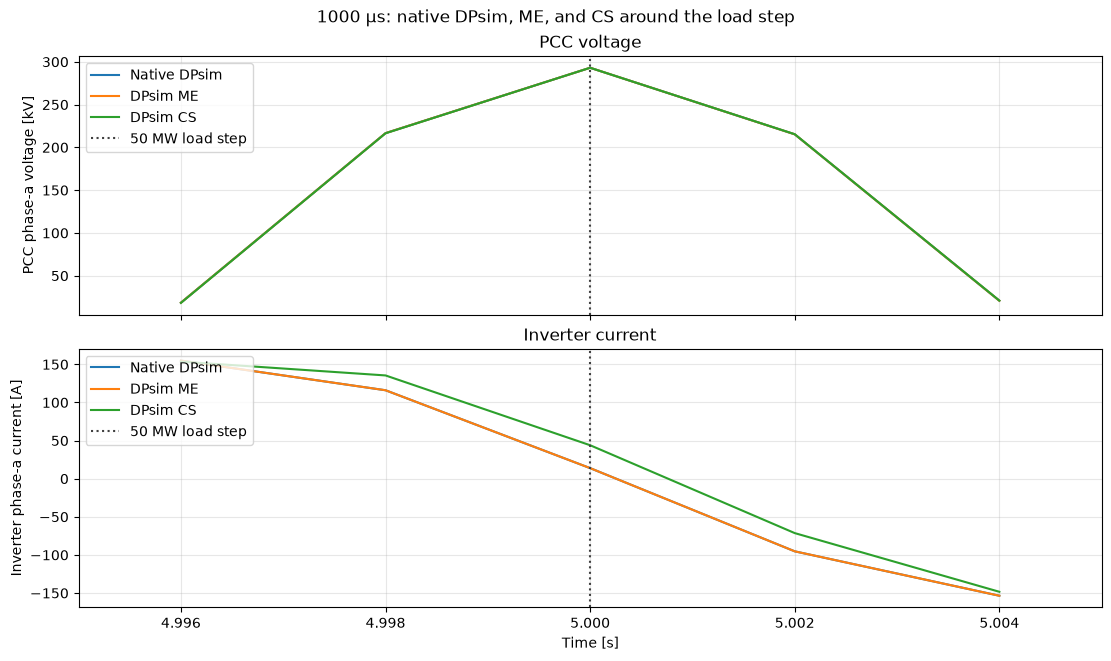

In [6]:
load_step = float(metrics["configuration"]["load_step_s"])
zoom_half_width = 0.005
for step in steps_us:
    case = metrics["cases"][str(step)]
    trace_paths = {
        "Native DPsim": case["native"]["compact_trace"],
        "DPsim ME": case["comparisons"]["me"]["compact_trace"],
        "DPsim CS": case["comparisons"]["cs"]["compact_trace"],
    }
    fig, axes = plt.subplots(
        2, 1, figsize=(11, 6.5), sharex=True, constrained_layout=True
    )
    for label, path in trace_paths.items():
        trace = pd.read_csv(path)
        trace = trace[
            (trace["time_s"] >= load_step - zoom_half_width)
            & (trace["time_s"] <= load_step + zoom_half_width)
        ]
        axes[0].plot(trace["time_s"], trace["v_a_V"] / 1000.0, label=label)
        axes[1].plot(trace["time_s"], trace["i_a_A"], label=label)
    for ax in axes:
        ax.axvline(load_step, color="0.25", linestyle=":", label="50 MW load step")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="upper left")
    axes[0].set_ylabel("PCC phase-a voltage [kV]")
    axes[0].set_title("PCC voltage")
    axes[1].set_ylabel("Inverter phase-a current [A]")
    axes[1].set_title("Inverter current")
    axes[1].set_xlabel("Time [s]")
    axes[1].set_xlim(load_step - zoom_half_width, load_step + zoom_half_width)
    fig.suptitle(f"{step} µs: native DPsim, ME, and CS around the load step")
    plt.show()

## Run definition and interpretation

- **Initialization:** the small grid is initialized from network powerflow. The native current-response filter and both FMU models start from the same 60 Hz periodic filter state; ME and CS use the importer’s powerflow-based FMU state initialization.
- **Transient:** a 50 MW load step is applied at 5 s in the closed-loop network.
- **Error baseline:** each ME or CS trace is compared with native DPsim at the identical timestep. This isolates implementation/coupling differences at a matched discretization; it does not make native DPsim an independent physical truth model.
- **RMS metrics:** full-run and pre/post load-step RMS errors use every original sample and all three phases. Time-history plots are decimated only after the 100 ms rolling error is calculated.
- **Reproduction:** from the repository root, run `python3 dpsim-fmi/examples/small_inverter_grid/run_dpsim_10s_sweep.py`. The source runner records per-case solver and process wall times alongside the trace data.

## 5 ms coarse-step stress test

This separate 10 s run uses a 5 ms timestep and the same powerflow start and 5 s load step. It completed with 2,001 samples per method. At 60 Hz, 5 ms provides only about 3.3 samples per cycle and equals the inverter current-response time constant, so treat this as a coarse-step stress test, not a waveform-accuracy case.

,Method,Voltage RMS error [%],Current RMS error [%]
0,Native DPsim,0,0
1,DPsim ME,3.0702e-10,1.6034e-08
2,DPsim CS,0.63326,131.61


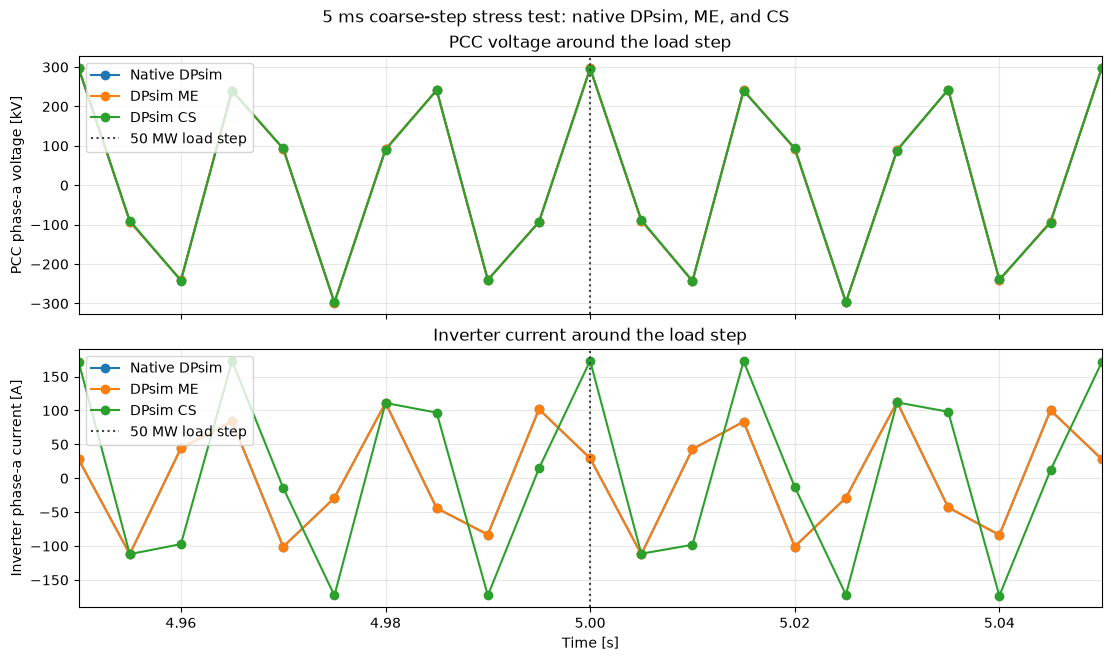

In [7]:
stress_dir = OUT.parent / "dpsim_5ms_stress"
stress = json.loads((stress_dir / "metrics.json").read_text())
stress_case = stress["cases"]["5000"]
stress_rows = [
    {
        "Method": "Native DPsim",
        "Voltage RMS error [%]": 0.0,
        "Current RMS error [%]": 0.0,
    }
]
for method in ("me", "cs"):
    result = stress_case["comparisons"][method]
    stress_rows.append(
        {
            "Method": f"DPsim {method.upper()}",
            "Voltage RMS error [%]": result["full_run"]["voltage"]["rms_error_percent"],
            "Current RMS error [%]": result["full_run"]["current"]["rms_error_percent"],
        }
    )
stress_summary = pd.DataFrame(stress_rows)
display(
    stress_summary.style.format(
        {"Voltage RMS error [%]": "{:.5g}", "Current RMS error [%]": "{:.5g}"}
    )
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, constrained_layout=True)
for label, path in (
    ("Native DPsim", stress_case["native"]["compact_trace"]),
    ("DPsim ME", stress_case["comparisons"]["me"]["compact_trace"]),
    ("DPsim CS", stress_case["comparisons"]["cs"]["compact_trace"]),
):
    trace = pd.read_csv(path)
    trace = trace[(trace["time_s"] >= 4.95) & (trace["time_s"] <= 5.05)]
    axes[0].plot(trace["time_s"], trace["v_a_V"] / 1000.0, marker="o", label=label)
    axes[1].plot(trace["time_s"], trace["i_a_A"], marker="o", label=label)
for ax in axes:
    ax.axvline(5.0, color="0.25", linestyle=":", label="50 MW load step")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper left")
axes[0].set_ylabel("PCC phase-a voltage [kV]")
axes[0].set_title("PCC voltage around the load step")
axes[1].set_ylabel("Inverter phase-a current [A]")
axes[1].set_title("Inverter current around the load step")
axes[1].set_xlabel("Time [s]")
axes[1].set_xlim(4.95, 5.05)
fig.suptitle("5 ms coarse-step stress test: native DPsim, ME, and CS")
plt.show()